# **Market Risk Analysis: VaR, Expected Shortfall, and Monte Carlo Simulation**

## **Project Overview**

This project aims to measure the market risk of a hypothetical $20 million corporate bond portfolio exposed to changes in interest rates and credit spreads.

Using historical financial data from the Federal Reserve Economic Data (FRED) database, we will estimate portfolio gains and losses and calculate Value at Risk (VaR) and Expected Shortfall (ES) using Historical Simulation and Monte Carlo Simulation.

We will also evaluate portfolio risk during periods of financial stress using Stressed VaR (SVaR) and briefly examine the relevance of these risk measures under the Fundamental Review of the Trading Book (FRTB) framework.

**1. Import Libraries**

**2. Data Wrangling**

- 2.1 Merging datasets
- 2.2 Inspecting missing values

**3. Feature Engineering**
 - 3.1 Credit Spread Calculation
 - 3.2 Daily Changes in Treasury Yields and Credit Spreads

**4. Exploratory Data Analysis**
- 4.1 Descriptive Statistics
- 4.2 Distribution and Outlier Analysis
- 4.3 Historical Trends

**5. Portfolio Profit & Loss (P&L) Calculation**

**6. Historical Value at Risk (VaR) and Expected Shortfall (ES)**

- 6.1 Historical Value at Risk (VaR)
- 6.2 Historical Expected Shortfall (ES)
- 6.3 Analytical Parametric Var and ES
- 6.4 Student's t Parametric VaR and Expected Shortfall
**7. Stressed Value at Risk (SVaR) and Stressed Expected Shortfall (Stressed ES)**
- 7.1 Historical Stressed Var and Expected Shortfall
- 7.2 Normal Parametric Stressed VaR and Expected Shortfall
- 7.3 Student's t Parametric Stressed VaR and Expected Shortfall
- 7.4 Comparison and Interpretation of Stressed Risk Estimates
**8. Monte Carlo Simulation**
- 8.1 Estimating Market Risk Factor Parameters
- 8.2 Generating Monte Carlo Scenarios
- 8.3 Simulated Portfolio P&L
- 8.4 Monte Carlo VaR and Expected Shortfall
Potential Extensions
- 8.5 Comparison of Risk Estimation Models
Comparative Analysis and Key Findings

**9. VaR Backtesting and Model Validation**

**10. Conclusions, Limitations, and Future Research**


## **1. Import Libraries**


In [ ]:
# Data manipulation and numerical computations
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

## **2. Data Wrangling**


In [ ]:
# Load 10-Year Treasury Yield
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"

treasury_df = pd.read_csv(url)

treasury_df.head()

,observation_date,DGS10
0,1962-01-02,4.06
1,1962-01-03,4.03
2,1962-01-04,3.99
3,1962-01-05,4.02
4,1962-01-08,4.03


In [ ]:
treasury_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16903 entries, 0 to 16902
Data columns (total 2 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   observation_date  16903 non-null  object 
 1   DGS10             16182 non-null  float64
dtypes: float64(1), object(1)
memory usage: 264.2+ KB


In [ ]:
treasury_df = treasury_df.rename(
    columns={
        "observation_date": "date",
        "DGS10": "treasury_yield"
    }
)

treasury_df["date"] = pd.to_datetime(treasury_df["date"])

treasury_df.head()

,date,treasury_yield
0,1962-01-02,4.06
1,1962-01-03,4.03
2,1962-01-04,3.99
3,1962-01-05,4.02
4,1962-01-08,4.03


In [ ]:
# Load Moody's Baa Corporate Bond Yield
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DBAA"

corporate_df = pd.read_csv(url)

corporate_df.head()

,observation_date,DBAA
0,1986-01-02,11.38
1,1986-01-03,11.35
2,1986-01-06,11.36
3,1986-01-07,11.29
4,1986-01-08,11.34


In [ ]:
corporate_df = corporate_df.rename(
    columns={
        "observation_date": "date",
        "DBAA": "corporate_yield"
    }
)

corporate_df["date"] = pd.to_datetime(corporate_df["date"])

corporate_df.head()

,date,corporate_yield
0,1986-01-02,11.38
1,1986-01-03,11.35
2,1986-01-06,11.36
3,1986-01-07,11.29
4,1986-01-08,11.34


In [ ]:
# Check dataset dimensions
print("Treasury dataset:", treasury_df.shape)
print("Corporate bond dataset:", corporate_df.shape)

Treasury dataset: (16903, 2)
Corporate bond dataset: (10642, 2)


### Merging datasets

In [ ]:
# Merge datasets by observation date
df = pd.merge(
    treasury_df,
    corporate_df,
    on="date",
    how="inner"
)

df.head()

,date,treasury_yield,corporate_yield
0,1986-01-02,9.04,11.38
1,1986-01-03,9.05,11.35
2,1986-01-06,9.07,11.36
3,1986-01-07,8.94,11.29
4,1986-01-08,9.13,11.34


In [ ]:
# Filter and sort historical data
df = df[df["date"] >= "2005-01-01"].copy()
df = df.sort_values("date").reset_index(drop=True)

In [ ]:
df.info()
df.isnull().sum()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5684 entries, 0 to 5683
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             5684 non-null   datetime64[ns]
 1   treasury_yield   5451 non-null   float64       
 2   corporate_yield  5451 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 133.3 KB


(5684, 3)

### Inspecting missing values

In [ ]:
# Check missing values
df.isnull().sum()

,0
date,0
treasury_yield,233
corporate_yield,233


In [ ]:
# Check whether both yield series have missing values on the same dates
(df["treasury_yield"].isna() == df["corporate_yield"].isna()).all()

np.False_

In [ ]:
# Count dates where only Treasury yield is missing
print("Only Treasury missing:",
      (df["treasury_yield"].isna() & df["corporate_yield"].notna()).sum())

# Count dates where only corporate yield is missing
print("Only Corporate missing:",
      (df["corporate_yield"].isna() & df["treasury_yield"].notna()).sum())

# Count dates where both yields are missing
print("Both missing:",
      (df["treasury_yield"].isna() & df["corporate_yield"].isna()).sum())

Only Treasury missing: 5
Only Corporate missing: 5
Both missing: 228


In [ ]:
# Inspect dates where only one yield is missing
df[
    df["treasury_yield"].isna() !=
    df["corporate_yield"].isna()
]

,date,treasury_yield,corporate_yield
1528,2010-11-11,NaN,5.97
3330,2017-10-09,NaN,4.34
3354,2017-11-10,2.40,NaN
3590,2018-10-08,NaN,5.08
4239,2021-04-02,1.72,NaN
4398,2021-11-11,NaN,3.23
4434,2021-12-31,1.52,NaN
4635,2022-10-10,NaN,6.17
4764,2023-04-07,3.39,NaN
5544,2026-04-03,4.35,NaN


After inspecting the missing values, we found that most correspond to market holidays or non-reporting days, while a small number result from differences in reporting calendars between Treasury and corporate bond yields.

We decided to remove observations with missing values in either series to ensure complete and aligned data for subsequent market risk calculations, including Value at Risk (VaR), Expected Shortfall (ES), and Monte Carlo simulation. Retaining incomplete observations could lead to inaccurate calculations of yield changes and portfolio gains and losses.

In [ ]:
df = df.dropna().reset_index(drop=True)

In [ ]:
# Verify cleaned dataset
print(df.shape)
print(df.isnull().sum())

(5446, 3)
date               0
treasury_yield     0
corporate_yield    0
dtype: int64


## **3. Feature Engineering**

### 3.1 Credit Spread Calculation

Credit spreads represent the difference between corporate bond yields and U.S. Treasury yields. They provide an indication of the additional compensation investors require for holding corporate bonds, which carry greater credit risk.

We calculate the credit spread by subtracting the 10-year Treasury yield from Moody's Baa corporate bond yield.

$$
\text{Credit Spread}_t = \text{Corporate Yield}_t - \text{Treasury Yield}_t
$$

The calculated credit spreads will be used to measure changes in credit market conditions and estimate their impact on our bond portfolio's value.

In [ ]:
# Calculate credit spread
df["credit_spread"] = df["corporate_yield"] - df["treasury_yield"]

In [ ]:
df.head()

,date,treasury_yield,corporate_yield,credit_spread
0,2005-01-03,4.23,6.09,1.86
1,2005-01-04,4.29,6.14,1.85
2,2005-01-05,4.29,6.12,1.83
3,2005-01-06,4.29,6.13,1.84
4,2005-01-07,4.29,6.12,1.83


A widening spread generally indicates increased preceived risk, while narrowing spread suggests improving credit market conditions.

### 3.2 Daily Changes in Treasury Yields and Credit Spreads

To measure daily movements in interest rates and credit spreads, we calculate the difference between consecutive observations.

$$
\Delta y_t = y_t - y_{t-1}
$$

$$
\Delta s_t = s_t - s_{t-1}
$$

Where:
- $\Delta y_t$ = Daily change in the Treasury yield
- $\Delta s_t$ = Daily change in the credit spread

We use absolute changes rather than percentage returns because bond price sensitivity is measured relative to changes in yield levels.

These daily changes will serve as the primary risk factors for estimating portfolio profit and loss (P&L), Value at Risk (VaR), and Expected Shortfall (ES).


In [ ]:
# Calculate daily changes in Treasury yields and credit spreads
df["treasury_change"] = df["treasury_yield"].diff()
df["spread_change"] = df["credit_spread"].diff()

df.head()

,date,treasury_yield,corporate_yield,credit_spread,treasury_change,spread_change
0,2005-01-03,4.23,6.09,1.86,NaN,NaN
1,2005-01-04,4.29,6.14,1.85,0.06,-0.01
2,2005-01-05,4.29,6.12,1.83,0.00,-0.02
3,2005-01-06,4.29,6.13,1.84,0.00,0.01
4,2005-01-07,4.29,6.12,1.83,0.00,-0.01


## **4. Exploratory Data Analysis**

### 4.1 Descriptive Statistics

We begin the exploratory data analysis by examining summary statistics for Treasury yields, corporate bond yields, credit spreads, and their daily changes.

Particular attention is given to standard deviation, minimum and maximum values, and the distribution of daily changes. These statistics help us understand historical market volatility and identify extreme movements that may influence portfolio risk estimates.

In [ ]:
# Summary statistics of market risk factors
df[[
    "treasury_yield",
    "corporate_yield",
    "credit_spread",
    "treasury_change",
    "spread_change"
]].describe().T

,count,mean,std,min,25%,50%,75%,max
treasury_yield,5446.0,3.028669,1.152596,0.52,2.08,2.90,4.11,5.31
corporate_yield,5446.0,5.425466,1.106913,3.11,4.69,5.44,6.15,9.54
credit_spread,5446.0,2.396798,0.785170,1.36,1.81,2.23,2.82,6.16
treasury_change,5445.0,0.000160,0.056345,-0.51,-0.03,0.00,0.03,0.29
spread_change,5445.0,-0.000077,0.030523,-0.20,-0.01,0.00,0.01,0.38


**Interpretation of Descriptive Statistics**

The descriptive statistics show that average daily changes in Treasury yields and credit spreads are close to zero, with relatively modest standard deviations of approximately 5.64 and 3.05 basis points, respectively.

However, Treasury yield changes range from −51 to +29 basis points, while credit spread changes range from −20 to +38 basis points. These extreme observations indicate that market movements can occasionally be significantly larger than typical daily fluctuations, highlighting the importance of measuring tail risk through Value at Risk (VaR) and Expected Shortfall (ES).

In [ ]:
# Five largest daily credit spread increases
df.nlargest(5, "spread_change")[
    ["date", "treasury_change", "spread_change"]
]

,date,treasury_change,spread_change
3797,2020-03-09,-0.20,0.38
947,2008-10-10,0.05,0.38
951,2008-10-17,-0.01,0.36
3804,2020-03-18,0.16,0.32
1053,2009-03-18,-0.51,0.28


In [ ]:
# Five largest daily credit spread decreases
df.nsmallest(5, "spread_change")[
    ["date", "treasury_change", "spread_change"]
]

,date,treasury_change,spread_change
3821,2020-04-13,0.03,-0.20
1109,2009-06-08,0.07,-0.14
1101,2009-05-27,0.21,-0.14
3820,2020-04-09,-0.04,-0.14
3859,2020-06-05,0.09,-0.13


The largest daily credit spread movements were concentrated around the 2008 financial crisis and the COVID-19 market disruption in 2020. The sharp spread tightening observed in April 2020 coincided with Federal Reserve interventions aimed at stabilizing credit markets, illustrating how quickly market conditions can change during periods of financial stress (April 9, 2020, was the day the Federal Reserve announced a major expansion of its emergency lending programs).

### 4.2 Distribution and Outlier Analysis

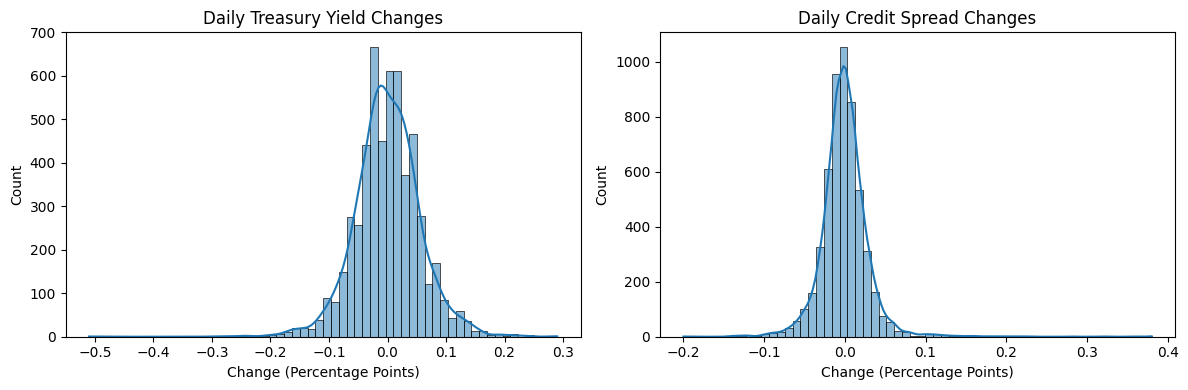

In [ ]:
# Distribution of daily changes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["treasury_change"].dropna(), bins=60,
             kde=True, ax=axes[0])
axes[0].set_title("Daily Treasury Yield Changes")
axes[0].set_xlabel("Change (Percentage Points)")

sns.histplot(df["spread_change"].dropna(), bins=60,
             kde=True, ax=axes[1])
axes[1].set_title("Daily Credit Spread Changes")
axes[1].set_xlabel("Change (Percentage Points)")

plt.tight_layout()
plt.show()

In [ ]:
# Calculate skewness and excess kurtosis
df[["treasury_change", "spread_change"]].agg(["skew", "kurt"])

,treasury_change,spread_change
skew,-0.139781,1.911814
kurt,2.802783,20.963391


The skewness results indicate that Treasury yield changes are approximately symmetric, with slight negative skewness (−0.14), while credit spread changes exhibit strong positive skewness (1.91).

Both distributions have positive excess kurtosis, particularly credit spread changes (20.96), indicating substantial tail risk and extreme observations relative to a normal distribution. These findings suggest that normally distributed Monte Carlo scenarios may not fully capture extreme market movements, highlighting the importance of comparing Monte Carlo risk estimates with historical simulation.

### 4.3 Historical Trends

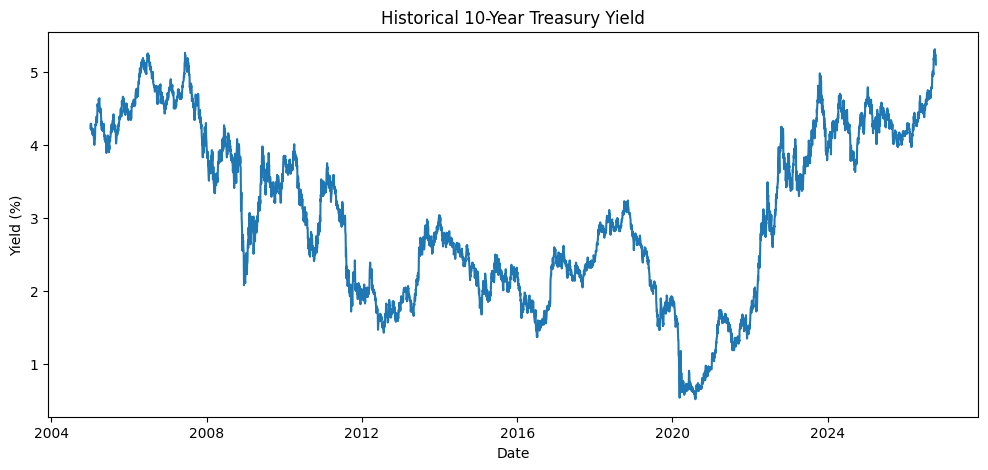

In [ ]:
# Plot historical Treasury yields
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["treasury_yield"])
plt.title("Historical 10-Year Treasury Yield")
plt.xlabel("Date")
plt.ylabel("Yield (%)")
plt.show()

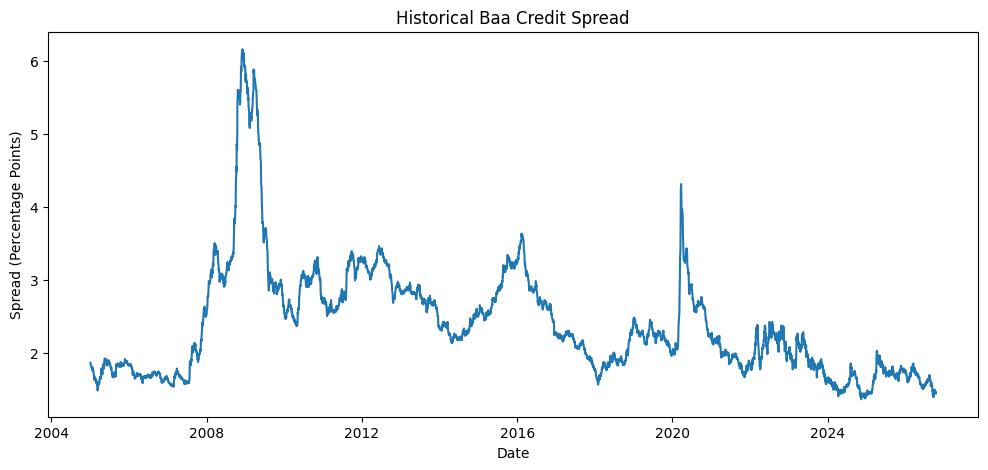

In [ ]:
# Plot historical credit spreads
plt.figure(figsize=(12, 5))
plt.plot(df["date"], df["credit_spread"])
plt.title("Historical Baa Credit Spread")
plt.xlabel("Date")
plt.ylabel("Spread (Percentage Points)")
plt.show()



The time-series plots illustrate significant changes in Treasury yields and corporate credit spreads between 2005 and 2026. Treasury yields generally declined until 2020, followed by a sharp increase beginning in 2022.

Credit spreads widened significantly during the 2008 financial crisis and the COVID-19 market disruption in 2020, reflecting heightened market uncertainty and perceived credit risk. These periods demonstrate how market conditions can affect interest rates and credit spreads differently, highlighting the importance of considering both risk factors when estimating portfolio losses.

## **5. Portfolio Profit & Loss (P&L) Calculation**

### 5.1 Portfolio Overview and Assumptions

In this section, we estimate the hypothetical daily profit and loss (P&L) of a corporate bond portfolio exposed to changes in Treasury yields and credit spreads.

We assume a bank's trading desk holds a long position in a $20 million corporate bond portfolio. The portfolio's value is sensitive to changes in interest rates and credit market conditions.

### Portfolio Assumptions

| Parameter | Assumed Value |
|---|---|
| Portfolio Market Value | $20,000,000 |
| Position | Long Corporate Bonds |
| Interest Rate Modified Duration | 4 years |
| Credit Spread Duration | 4 years |
| Risk Factors | Treasury Yield and Credit Spread Changes |
| Historical Data | FRED Daily Observations |

Both duration measures are assumed to be 4 years for simplicity. In practice, banks calculate portfolio risk sensitivities using bond pricing and risk management systems.

### 5.2 Portfolio P&L Methodology

Bond prices generally move inversely to changes in yields. To estimate the impact of daily market movements on our portfolio, we use a first-order duration approximation.

$$
\Delta P \approx -P(D_r \Delta y + D_s \Delta s)
$$

Where:

- $P$ = Portfolio market value
- $D_r$ = Interest rate modified duration
- $D_s$ = Credit spread duration
- $\Delta y$ = Daily change in Treasury yield
- $\Delta s$ = Daily change in credit spread
- $\Delta P$ = Estimated change in portfolio value (P&L)

The calculation separates the contributions of interest rate movements and credit spread movements.

$$
P\&L_{\text{Treasury}} = -P \times D_r \times \Delta y
$$

$$
P\&L_{\text{Spread}} = -P \times D_s \times \Delta s
$$

Total portfolio P&L is calculated as:

$$
P\&L_{\text{Total}} = P\&L_{\text{Treasury}} + P\&L_{\text{Spread}}
$$

Since FRED reports yields in percentage points, daily changes must be divided by 100 before applying the duration formula.

## 5.3 Historical P&L Calculation

We apply historical daily Treasury yield and credit spread changes to our hypothetical portfolio to estimate daily gains and losses.

We also examine March 9, 2020, a period of significant market stress, when Treasury yields declined and corporate credit spreads widened sharply.

The resulting historical P&L distribution will serve as the foundation for estimating **Value at Risk (VaR)** and **Expected Shortfall (ES)**.

These estimates represent hypothetical mark-to-market gains and losses, rather than actual realized trading results.

In [ ]:
# Define hypothetical portfolio assumptions
portfolio_value = 20_000_000
duration_rates = 4
duration_spread = 4

# Calculate P&L from Treasury yield changes
df["pnl_treasury"] = (
    -portfolio_value * duration_rates
    * df["treasury_change"] / 100
)

# Calculate P&L from credit spread changes
df["pnl_spread"] = (
    -portfolio_value * duration_spread
    * df["spread_change"] / 100
)

# Calculate total portfolio P&L
df["portfolio_pnl"] = df["pnl_treasury"] + df["pnl_spread"]

# Preview results
df[["date", "pnl_treasury", "pnl_spread", "portfolio_pnl"]].dropna().head()

,date,pnl_treasury,pnl_spread,portfolio_pnl
1,2005-01-04,-48000.0,8000.0,-40000.0
2,2005-01-05,-0.0,16000.0,16000.0
3,2005-01-06,-0.0,-8000.0,-8000.0
4,2005-01-07,-0.0,8000.0,8000.0
5,2005-01-10,-0.0,8000.0,8000.0


In [ ]:
# Examine portfolio P&L during the March 2020 market stress
scenario = df.loc[
    df["date"] == "2020-03-09",
    ["date", "treasury_change", "spread_change",
     "pnl_treasury", "pnl_spread", "portfolio_pnl"]
]

display(scenario)

,date,treasury_change,spread_change,pnl_treasury,pnl_spread,portfolio_pnl
3797,2020-03-09,-0.2,0.38,160000.0,-304000.0,-144000.0


**Interpretation of Portfolio P&L**

Historical portfolio P&L was estimated by applying daily changes in Treasury yields and credit spreads to a hypothetical USD 20 million corporate bond portfolio using a modified duration approximation.

The calculations show how changes in interest rates and credit spreads contribute separately to daily portfolio gains and losses.

For example, during the COVID-19 market disruption on March 9, 2020, Treasury yields declined by 20 basis points, generating a hypothetical gain of USD 160,000. However, credit spreads widened by 38 basis points, resulting in a loss of USD 304,000. The net portfolio P&L was therefore USD -144,000, illustrating how credit spread risk can outweigh the benefits of declining Treasury yields during periods of market stress.


## **6. Historical Value at Risk (VaR) and Expected Shortfall (ES)**

In this section, we estimate the market risk of our hypothetical USD 20 million corporate bond portfolio using historical simulation.

We use daily portfolio P&L observations from January 2005 through the latest available date in 2026. This extended historical period captures different market environments, including the 2008 financial crisis, the COVID-19 market disruption, and more recent interest-rate movements.

The historical P&L distribution calculated in Section 5 is used to estimate one-day Value at Risk (VaR) and Expected Shortfall (ES) at the 95% and 99% confidence levels.

We will also analyze the September 2008–August 2009 financial crisis separately to evaluate portfolio risk under concentrated periods of severe market stress.






### **6.1 Historical Value at Risk (VaR)**

**Value at Risk (VaR)** is a statistical measure that estimates how much a portfolio could lose over a specified period at a given confidence level.

For example:

- **95% one-day VaR:** According to our model, there is a 95% probability that the portfolio will not lose more than the estimated VaR amount over one trading day.
- **99% one-day VaR:** According to our model, there is a 99% probability that the portfolio will not lose more than the estimated VaR amount over one trading day.

Historical Simulation calculates VaR using actual historical market movements to estimate potential portfolio losses.

For a 95% confidence level:

$$
VaR_{95\%} = -Q_{0.05}(P\&L)
$$

For a 99% confidence level:

$$
VaR_{99\%} = -Q_{0.01}(P\&L)
$$

VaR estimates a potential loss threshold but does not tell us how large losses could become beyond that amount.


In [ ]:
# Select recent historical data (2023–2026)
full_df = df[df["date"] >= "2005-01-01"].copy()

# Extract daily portfolio P&L
full_pnl = full_df["portfolio_pnl"].dropna()

# Check number of observations
print("Number of observations:", len(full_pnl))

Number of observations: 5445


In [ ]:
# Calculate one-day Historical VaR
var_95 = -full_pnl.quantile(0.05)
var_99 = -full_pnl.quantile(0.01)

print(f"95% Historical VaR: ${var_95:,.2f}")
print(f"99% Historical VaR: ${var_99:,.2f}")

95% Historical VaR: $72,000.00
99% Historical VaR: $112,000.00


**Interpretation of Historical VaR**

The 95% one-day Historical VaR is USD 72,000, indicating that, according to our model, there is a 95% probability that the portfolio will not lose more than this amount over one trading day.

At the 99% confidence level, VaR increases to USD 112,000, indicating a 99% probability that daily losses will not exceed this amount.

However, VaR does not measure the severity of losses beyond these thresholds. Expected Shortfall (ES) will be used to estimate the average loss in these extreme scenarios.

### **6.2 Historical Expected Shortfall (ES)**

**Expected Shortfall (ES)**, also known as Conditional Value at Risk (CVaR), measures the average loss in the worst tail of the portfolio's loss distribution.

Unlike VaR, which identifies a loss threshold, ES estimates the average severity of losses beyond that threshold.

For example:

- **95% ES:** Average loss among the worst 5% of portfolio outcomes.
- **99% ES:** Average loss among the worst 1% of portfolio outcomes.

Expected Shortfall provides additional information about extreme losses and is particularly useful for measuring tail risk during periods of market stress.

In this project, ES will be calculated from the same historical P&L distribution used for VaR, allowing us to compare the two risk measures.

The results will help us evaluate the portfolio's potential downside exposure before moving to Monte Carlo simulation and Stressed VaR.

In [ ]:
# Select the worst 5% and 1% of daily P&L outcomes
worst_5 = full_pnl.nsmallest(int(np.ceil(len(full_pnl) * 0.05)))
worst_1 = full_pnl.nsmallest(int(np.ceil(len(full_pnl) * 0.01)))

# Calculate Historical Expected Shortfall
es_95 = -worst_5.mean()
es_99 = -worst_1.mean()

print(f"95% Historical ES: ${es_95:,.2f}")
print(f"99% Historical ES: ${es_99:,.2f}")

95% Historical ES: $98,783.88
99% Historical ES: $151,272.73


**Interpretation of Historical Expected Shortfall**

The 95% Historical Expected Shortfall is USD 98,783.88, representing the average loss among the worst 5% of daily portfolio outcomes during the 2005–2026 period.

At the 99% confidence level, Expected Shortfall increases to USD 151,272.73, representing the average loss among the worst 1% of outcomes.

Both ES estimates are higher than their corresponding VaR estimates, demonstrating that losses can be substantially larger than the VaR thresholds. Expected Shortfall therefore provides additional insight into the severity of potential losses under extreme market conditions.

### **6.3 Analytical Parametric Var and ES**
In this section, we calculate one-day parametric Value at Risk (VaR) and Expected Shortfall (ES) at the 95% and 99% confidence levels.

Unlike historical simulation, which uses the observed P&L distribution directly, the parametric approach assumes that portfolio P&L follows a normal distribution. We use the historical mean and standard deviation of daily portfolio P&L from 2023–2026 to estimate potential losses using analytical formulas.

These estimates provide an additional benchmark for comparison with historical VaR and ES, and later with our normal Monte Carlo simulation, helping us evaluate how the normality assumption affects measured portfolio risk.


In [ ]:
# Estimate portfolio P&L parameters
mean_pnl = full_pnl.mean()
std_pnl = full_pnl.std()

# Parametric VaR
param_var_95 = stats.norm.ppf(0.95) * std_pnl - mean_pnl
param_var_99 = stats.norm.ppf(0.99) * std_pnl - mean_pnl

# Parametric Expected Shortfall
param_es_95 = (
    std_pnl * stats.norm.pdf(stats.norm.ppf(0.95)) / 0.05
    - mean_pnl
)

param_es_99 = (
    std_pnl * stats.norm.pdf(stats.norm.ppf(0.99)) / 0.01
    - mean_pnl
)

print(f"95% Parametric VaR: ${param_var_95:,.2f}")
print(f"99% Parametric VaR: ${param_var_99:,.2f}")
print(f"95% Parametric ES: ${param_es_95:,.2f}")
print(f"99% Parametric ES: ${param_es_99:,.2f}")

95% Parametric VaR: $70,308.84
99% Parametric VaR: $99,411.74
95% Parametric ES: $88,153.33
99% Parametric ES: $113,882.88


The normal parametric model produces lower VaR and Expected Shortfall estimates than historical simulation, particularly at the 99% confidence level.

For example, 99% ES is USD 113,882.88, compared with USD 151,272.73 under historical simulation.

This suggests that the normality assumption may underestimate extreme losses because it does not fully capture the heavy tails and asymmetry observed in historical market movements.

### **6.4 Student's t Parametric VaR and Expected Shortfall**

To account for the heavy tails observed in our historical data, we extend our parametric risk analysis using a Student's t-distribution instead of a normal distribution.

Unlike the normal distribution, Student's t allows for more frequent extreme outcomes, depending on its estimated degrees of freedom.

We fit the distribution to our historical portfolio P&L and calculate one-day VaR and Expected Shortfall at the 95% and 99% confidence levels.

The results will be compared with historical VaR and normal parametric VaR to examine how distributional assumptions affect estimated portfolio risk.

In [ ]:
# Fit Student's t-distribution to historical portfolio P&L
# Use thousands of dollars for numerical stability
pnl_thousands = full_pnl / 1000

dof, center, scale = stats.t.fit(pnl_thousands)

print(f"Estimated degrees of freedom: {dof:.2f}")

# Calculate Student's t VaR and Expected Shortfall
if dof <= 1:
    raise ValueError("Expected Shortfall is not finite when dof <= 1.")

def student_t_risk(confidence):
    tail = 1 - confidence
    cutoff = stats.t.ppf(tail, dof)

    var = -(center + scale * cutoff) * 1000

    es = (
        -center
        + scale * (dof + cutoff**2) / (dof - 1)
        * stats.t.pdf(cutoff, dof) / tail
    ) * 1000

    return var, es

t_var_95, t_es_95 = student_t_risk(0.95)
t_var_99, t_es_99 = student_t_risk(0.99)

print(f"Student's t 95% VaR: ${t_var_95:,.2f}")
print(f"Student's t 99% VaR: ${t_var_99:,.2f}")
print(f"Student's t 95% ES: ${t_es_95:,.2f}")
print(f"Student's t 99% ES: ${t_es_99:,.2f}")

Estimated degrees of freedom: 5.72
Student's t 95% VaR: $66,439.02
Student's t 99% VaR: $108,712.99
Student's t 95% ES: $93,571.42
Student's t 99% ES: $140,705.59


The Student's t-distribution was fitted with approximately 5.72 degrees of freedom, allowing for heavier tails than the normal distribution.

At the 99% confidence level, Student's t VaR is USD 108,712.99 and ES is USD 140,705.59, both substantially closer to the historical estimates than the normal parametric results.

This suggests that accounting for heavy tails can improve the representation of extreme losses in our sample. However, Student's t remains symmetric and does not fully capture skewness in the historical P&L distribution.

# **7. Stressed Value at Risk (SVaR) and Stressed Expected Shortfall (Stressed ES)**

In this section, we evaluate potential portfolio losses under severe market conditions using a 12-month stress period from September 2008 through August 2009, capturing the global financial crisis and its aftermath.

We calculate one-day stressed VaR and Expected Shortfall at the 95% and 99% confidence levels using three methods:

1. **Historical Simulation** — Uses observed portfolio P&L during the stress period.
2. **Normal Parametric** — Estimates risk using the mean and standard deviation of stressed P&L, assuming a normal distribution.
3. **Student's t Parametric** — Fits a Student's t-distribution to stressed P&L to account for heavier tails.

We compare the three methods to examine how distributional assumptions affect estimated losses during financial stress. We also compare stressed results with our full-history baseline from 2005–2026.

*Note: This is a simplified stressed risk analysis rather than a full regulatory implementation of Stressed VaR or stress-calibrated Expected Shortfall.*

## **7.1 Historical Stressed Var and Expected Shortfall**

In [ ]:
# Select the 2008–2009 financial crisis stress period
stress_df = df[
    (df["date"] >= "2008-09-01") &
    (df["date"] < "2009-09-01")
].copy()

# Extract historical portfolio P&L
stress_pnl = stress_df["portfolio_pnl"].dropna()

print("Number of stress observations:", len(stress_pnl))

Number of stress observations: 250


In [ ]:
# Calculate one-day Stressed VaR
svar_95 = -stress_pnl.quantile(0.05)
svar_99 = -stress_pnl.quantile(0.01)

print(f"95% Stressed VaR: ${svar_95:,.2f}")
print(f"99% Stressed VaR: ${svar_99:,.2f}")

95% Stressed VaR: $124,400.00
99% Stressed VaR: $180,080.00


In [ ]:
# Calculate Stressed Expected Shortfall
worst_stress_5 = stress_pnl.nsmallest(int(np.ceil(len(stress_pnl) * 0.05)))
worst_stress_1 = stress_pnl.nsmallest(int(np.ceil(len(stress_pnl) * 0.01)))

stress_es_95 = -worst_stress_5.mean()
stress_es_99 = -worst_stress_1.mean()

print(f"95% Stressed ES: ${stress_es_95:,.2f}")
print(f"99% Stressed ES: ${stress_es_99:,.2f}")

95% Stressed ES: $179,076.92
99% Stressed ES: $269,333.33


## **7.2 Normal Parametric Stressed VaR and Expected Shortfall**

We extend our stress analysis by calculating normal and Student's t parametric VaR and Expected Shortfall using the same September 2008–August 2009 P&L observations.

The normal model assumes a symmetric, bell-shaped distribution, while Student's t allows for heavier tails and more extreme outcomes.

Comparing these methods helps us evaluate how distributional assumptions affect risk estimates during periods of financial stress.

In [ ]:
# Estimate stressed portfolio P&L parameters
stress_mean = stress_pnl.mean()
stress_std = stress_pnl.std()

# Calculate normal parametric stressed VaR
normal_svar_95 = stats.norm.ppf(0.95) * stress_std - stress_mean
normal_svar_99 = stats.norm.ppf(0.99) * stress_std - stress_mean

# Calculate normal parametric stressed ES
normal_ses_95 = (
    stress_std * stats.norm.pdf(stats.norm.ppf(0.95)) / 0.05
    - stress_mean
)

normal_ses_99 = (
    stress_std * stats.norm.pdf(stats.norm.ppf(0.99)) / 0.01
    - stress_mean
)

print(f"95% Normal Stressed VaR: ${normal_svar_95:,.2f}")
print(f"99% Normal Stressed VaR: ${normal_svar_99:,.2f}")
print(f"95% Normal Stressed ES: ${normal_ses_95:,.2f}")
print(f"99% Normal Stressed ES: ${normal_ses_99:,.2f}")

95% Normal Stressed VaR: $127,014.20
99% Normal Stressed VaR: $180,619.71
95% Normal Stressed ES: $159,882.50
99% Normal Stressed ES: $207,274.53


## **7.3 Student's t Parametric Stressed VaR and Expected Shortfall**

In [ ]:
# Fit Student's t to stressed P&L (in thousands of dollars)
stress_pnl_thousands = stress_pnl / 1000

stress_dof, stress_center, stress_scale = stats.t.fit(
    stress_pnl_thousands
)

print(f"Estimated degrees of freedom: {stress_dof:.2f}")

if stress_dof <= 1:
    raise ValueError("Expected Shortfall is not finite when dof <= 1.")

# Calculate Student's t stressed VaR and ES
def stressed_student_t_risk(confidence):
    tail = 1 - confidence
    cutoff = stats.t.ppf(tail, stress_dof)

    var = -(stress_center + stress_scale * cutoff) * 1000

    es = (
        -stress_center
        + stress_scale * (stress_dof + cutoff**2) / (stress_dof - 1)
        * stats.t.pdf(cutoff, stress_dof) / tail
    ) * 1000

    return var, es

t_svar_95, t_ses_95 = stressed_student_t_risk(0.95)
t_svar_99, t_ses_99 = stressed_student_t_risk(0.99)

print(f"95% Student's t Stressed VaR: ${t_svar_95:,.2f}")
print(f"99% Student's t Stressed VaR: ${t_svar_99:,.2f}")
print(f"95% Student's t Stressed ES: ${t_ses_95:,.2f}")
print(f"99% Student's t Stressed ES: ${t_ses_99:,.2f}")

Estimated degrees of freedom: 7.77
95% Student's t Stressed VaR: $121,613.38
99% Student's t Stressed VaR: $192,510.15
95% Student's t Stressed ES: $166,401.21
99% Student's t Stressed ES: $240,419.61


## **7.4 Comparison and Interpretation of Stressed Risk Estimates**

In [ ]:
# Compare stressed risk estimates across methods
stress_comparison = pd.DataFrame({
    "Historical": [
        svar_95, svar_99, stress_es_95, stress_es_99
    ],
    "Normal Parametric": [
        normal_svar_95, normal_svar_99,
        normal_ses_95, normal_ses_99
    ],
    "Student's t Parametric": [
        t_svar_95, t_svar_99, t_ses_95, t_ses_99
    ]
}, index=["95% VaR", "99% VaR", "95% ES", "99% ES"])

display(stress_comparison.style.format("${:,.2f}"))

,Historical,Normal Parametric,Student's t Parametric
95% VaR,"$124,400.00","$127,014.20","$121,613.38"
99% VaR,"$180,080.00","$180,619.71","$192,510.15"
95% ES,"$179,076.92","$159,882.50","$166,401.21"
99% ES,"$269,333.33","$207,274.53","$240,419.61"




The normal parametric model produces VaR estimates remarkably close to historical simulation at both confidence levels, despite relying on a relatively simple normal distribution assumption.

However, larger differences appear in Expected Shortfall, particularly at the 99% confidence level. Normal parametric ES is approximately USD 62,059 below historical ES, suggesting that the normal distribution does not fully capture the severity of extreme losses observed during the crisis.

Student's t produces a closer 99% ES estimate, with a difference of approximately USD 28,914, reflecting its ability to account for heavier tails.

These results highlight that a model can estimate VaR thresholds reasonably closely while still underestimating losses beyond those thresholds. However, the historical stress sample contains only 250 observations, making extreme-tail estimates sensitive to a small number of outcomes.

# **8. Monte Carlo Simulation**

Monte Carlo simulation estimates potential outcomes by generating a large number of hypothetical scenarios based on specified probability distributions.

We use historical Treasury yield and credit spread changes from 2005–2026 to estimate their statistical properties and generate 10,000 hypothetical one-day market scenarios.

Our initial approach assumes a multivariate normal distribution, incorporating the historical means, volatilities, and covariance of the two risk factors.

We apply these simulated market movements to our USD 20 million corporate bond portfolio to calculate P&L and estimate VaR and Expected Shortfall at the 95% and 99% confidence levels.

The results will be compared with our historical and parametric risk estimates.


### **8.1 Estimating Market Risk Factor Parameters**

Before generating Monte Carlo scenarios, we estimate the historical mean, standard deviation, and correlation of daily Treasury yield changes and credit spread changes.

These parameters allow us to simulate market movements that reflect the historical average, volatility, and relationship between the two risk factors, under our assumed multivariate normal distribution.

In [ ]:
# Select daily market risk factor changes
risk_factors = full_df[
    ["treasury_change", "spread_change"]
].dropna()

# Estimate statistical parameters
risk_stats = risk_factors.agg(["mean", "std"]).T

display(risk_stats)



,mean,std
treasury_change,0.000160,0.056345
spread_change,-0.000077,0.030523


The average daily changes in Treasury yields and credit spreads are close to zero, indicating small net movements over the historical period. The standard deviations of 5.63 and 3.05 basis points, respectively, show that Treasury yields exhibited greater daily variability than credit spreads.

These statistical parameters will be used to generate simulated market movements in our Monte Carlo analysis.

In [ ]:
# Correlation Matrix
corr_matrix = risk_factors.corr()
display(corr_matrix)

,treasury_change,spread_change
treasury_change,1.000000,-0.365429
spread_change,-0.365429,1.000000


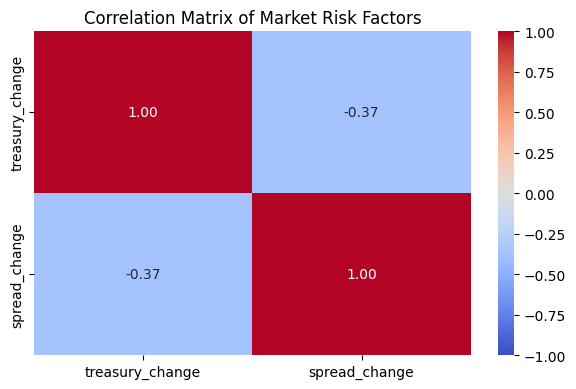

In [ ]:
# Plot correlation matrix heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    risk_factors.corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Matrix of Market Risk Factors")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate covariance matrix
cov_matrix = risk_factors.cov()

display(cov_matrix)

,treasury_change,spread_change
treasury_change,0.003175,-0.000628
spread_change,-0.000628,0.000932


The historical correlation between daily Treasury yield changes and credit spread changes is approximately -0.365, indicating a moderate negative relationship during 2005–2026.

This suggests that increases in Treasury yields have generally tended to coincide with narrowing credit spreads, and vice versa.

The covariance matrix incorporates both the variability of each risk factor and their relationship, allowing us to generate correlated Monte Carlo scenarios.

### **8.2 Generating Monte Carlo Scenarios**

In this section, we generate 10,000 hypothetical daily market scenarios using the historical statistical parameters estimated in Section 8.1.

First, we calculate the covariance matrix, which incorporates both the volatility of Treasury yield and credit spread changes and the relationship between them.

We then use the historical means and covariance matrix to generate correlated random scenarios, assuming a multivariate normal distribution.

These simulated market movements will be used to calculate hypothetical portfolio P&L and estimate Monte Carlo Value at Risk (VaR) and Expected Shortfall (ES) at the 95% and 99% confidence levels.

In [ ]:
# Define number of simulations
n_simulations = 10_000

# Estimate historical means
mean_changes = risk_factors.mean()

# Generate correlated Monte Carlo scenarios
rng = np.random.default_rng(42)

simulated_changes = rng.multivariate_normal(
    mean=mean_changes,
    cov=cov_matrix,
    size=n_simulations
)

# Convert simulation results into a DataFrame
simulated_df = pd.DataFrame(
    simulated_changes,
    columns=["treasury_change", "spread_change"]
)

simulated_df.head()

,treasury_change,spread_change
0,-0.024155,-0.023508
1,-0.035214,0.036090
2,0.100126,-0.063463
3,-0.009201,-0.006688
4,-0.004871,-0.023190


In [ ]:
# Check simulated means and standard deviations
display(simulated_df.agg(["mean", "std"]).T)

# Check simulated correlation
display(simulated_df.corr())

,mean,std
treasury_change,0.000359,0.055831
spread_change,0.000219,0.031068


,treasury_change,spread_change
treasury_change,1.000000,-0.364277
spread_change,-0.364277,1.000000


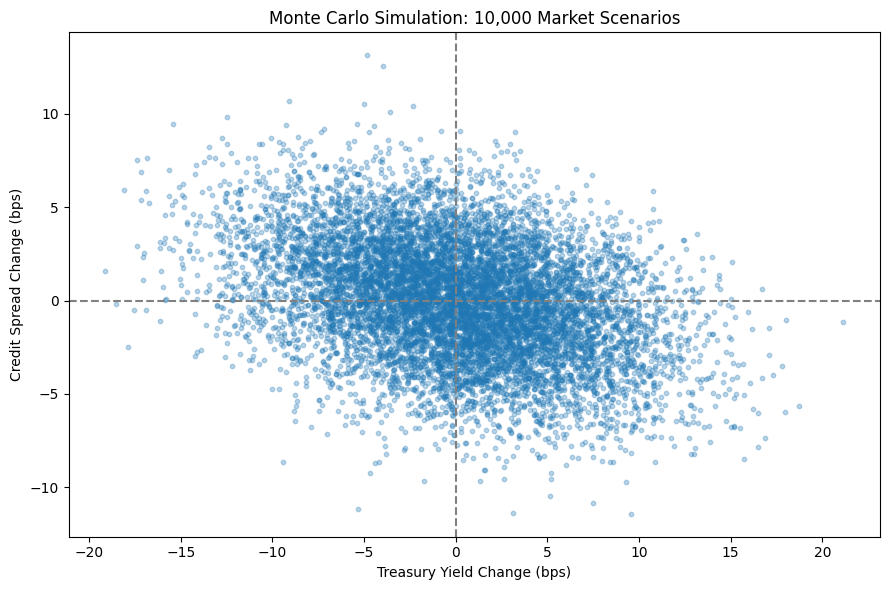

In [ ]:
# Visualize 10,000 Monte Carlo scenarios
plt.figure(figsize=(9, 6))

plt.scatter(
    simulated_df["treasury_change"] * 100,
    simulated_df["spread_change"] * 100,
    alpha=0.3,
    s=10
)

plt.title("Monte Carlo Simulation: 10,000 Market Scenarios")
plt.xlabel("Treasury Yield Change (bps)")
plt.ylabel("Credit Spread Change (bps)")

plt.axhline(0, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.tight_layout()
plt.show()

The simulated market movements closely reproduce the historical statistical parameters, including the negative correlation between Treasury yield changes and credit spread changes (-0.364 simulated versus -0.365 historically).

The scatter plot illustrates this negative relationship, with most simulated scenarios concentrated near zero and fewer extreme movements.

Each point represents one hypothetical one-day market scenario, which will be used to calculate portfolio P&L and estimate Monte Carlo VaR and Expected Shortfall.

### **8.3 Simulated Portfolio P&L**

We apply the same duration-based P&L approximation used in Section 5 to the 10,000 simulated market scenarios.

Each scenario represents a hypothetical one-day movement in Treasury yields and credit spreads, applied to our existing USD 20 million corporate bond portfolio.

We calculate the P&L contribution from each risk factor and combine them to obtain 10,000 simulated portfolio P&L outcomes, which will be used to estimate Monte Carlo VaR and Expected Shortfall.

In [55]:
portfolio_value = 20_000_000
duration_rates = 4
duration_spread = 4

In [56]:
# Calculate simulated P&L from Treasury yield changes
simulated_df["pnl_treasury"] = (
    -portfolio_value * duration_rates
    * simulated_df["treasury_change"] / 100
)

# Calculate simulated P&L from credit spread changes
simulated_df["pnl_spread"] = (
    -portfolio_value * duration_spread
    * simulated_df["spread_change"] / 100
)

# Calculate total simulated portfolio P&L
simulated_df["portfolio_pnl"] = (
    simulated_df["pnl_treasury"] + simulated_df["pnl_spread"]
)

# Preview simulated P&L
simulated_df.head()

,treasury_change,spread_change,pnl_treasury,pnl_spread,portfolio_pnl
0,-0.024155,-0.023508,19324.139246,18806.190027,38130.329273
1,-0.035214,0.036090,28171.525652,-28872.330276,-700.804623
2,0.100126,-0.063463,-80101.199977,50770.406421,-29330.793556
3,-0.009201,-0.006688,7360.744835,5350.785535,12711.530370
4,-0.004871,-0.023190,3896.873842,18551.700031,22448.573873


### **8.4 Monte Carlo VaR and Expected Shortfall**

Using the 10,000 simulated portfolio P&L outcomes, we estimate one-day Value at Risk (VaR) and Expected Shortfall (ES) at the 95% and 99% confidence levels.

First, we visualize the simulated P&L distribution to examine potential gains, losses, and tail risk.

We then calculate VaR using the 5th and 1st percentiles of the P&L distribution and ES as the average loss within the worst 5% and 1% of simulated outcomes.

These results will be compared with our historical and stressed risk estimates to evaluate how different modeling approaches affect measured portfolio risk.

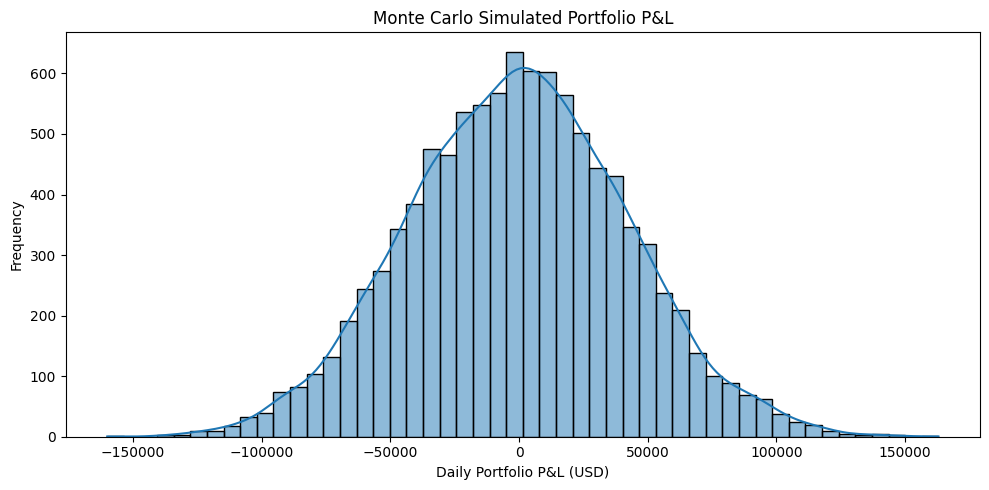

In [57]:
# Extract simulated portfolio P&L
mc_pnl = simulated_df["portfolio_pnl"]

# Plot simulated P&L distribution
plt.figure(figsize=(10, 5))

sns.histplot(mc_pnl, bins=50, kde=True)

plt.title("Monte Carlo Simulated Portfolio P&L")
plt.xlabel("Daily Portfolio P&L (USD)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [58]:
# Calculate Monte Carlo VaR
mc_var_95 = -mc_pnl.quantile(0.05)
mc_var_99 = -mc_pnl.quantile(0.01)

print(f"Monte Carlo 95% VaR: ${mc_var_95:,.2f}")
print(f"Monte Carlo 99% VaR: ${mc_var_99:,.2f}")# Select worst 5% and 1% of simulated P&L


Monte Carlo 95% VaR: $69,899.86
Monte Carlo 99% VaR: $96,912.46


In [59]:
# Select worst 5% and 1% of simulated P&L
worst_5_mc = mc_pnl.nsmallest(int(np.ceil(len(mc_pnl) * 0.05)))
worst_1_mc = mc_pnl.nsmallest(int(np.ceil(len(mc_pnl) * 0.01)))

# Calculate Monte Carlo Expected Shortfall
mc_es_95 = -worst_5_mc.mean()
mc_es_99 = -worst_1_mc.mean()

print(f"Monte Carlo 95% ES: ${mc_es_95:,.2f}")
print(f"Monte Carlo 99% ES: ${mc_es_99:,.2f}")

Monte Carlo 95% ES: $87,165.57
Monte Carlo 99% ES: $110,415.93


The simulated portfolio P&L follows an approximately normal distribution, consistent with the multivariate normal assumption used to generate Treasury yield and credit spread changes.

The Monte Carlo model estimates 95% and 99% VaR of approximately USD 69,900 and USD 96,912, respectively. The corresponding Expected Shortfall estimates are USD 87,166 and USD 110,416.

These results are relatively close to the analytical normal parametric estimates, providing a useful consistency check between the two approaches.

However, the Monte Carlo estimates are generally lower than the historical estimates, particularly for 99% Expected Shortfall. This suggests that the normality assumption may not adequately capture the skewness and heavy tails observed in historical market movements.

### Potential Extensions

Future research could explore alternative Monte Carlo approaches, including Student's t distributions, historical bootstrapping, and more flexible distributions such as Johnson SU.

Another potential extension is GARCH modeling, which allows volatility to change over time rather than assuming a constant volatility level.

These approaches could help capture additional features of financial market behavior, although their performance would need to be evaluated through model validation and backtesting.

### 8.5 Comparison of Risk Estimation Models

This section consolidates the one-day Value at Risk (VaR) and Expected Shortfall (ES) estimates obtained using historical simulation, normal and Student's t parametric methods, and normal Monte Carlo simulation.

We also include stressed estimates calibrated to the September 2008–August 2009 financial crisis period.

All estimates are based on the same hypothetical USD 20 million corporate bond portfolio, with an interest-rate duration and spread duration of 4.

The full-history models use data from 2005–2026, while stressed models use the 2008–2009 crisis period. The results are presented together to compare modeling assumptions and the impact of stress-period calibration.

In [63]:
# Consolidated comparison of VaR and Expected Shortfall

comparison_df = pd.DataFrame([
    ["2005–2026", "Historical Simulation", 72000, 112000, 98783.88, 151272.73],
    ["2005–2026", "Normal Parametric", 70308.84, 99411.74, 88153.33, 113882.88],
    ["2005–2026", "Student's t Parametric", 66439.02, 108712.99, 93571.42, 140705.59],
    ["2005–2026", "Normal Monte Carlo", 69899.86, 96912.46, 87165.57, 110415.93],
    ["2008–2009", "Historical Stressed", 124400, 180080, 179076.92, 269333.33],
    ["2008–2009", "Normal Parametric Stressed", 127014.20, 180619.71, 159882.50, 207274.53],
    ["2008–2009", "Student's t Stressed", 121613.38, 192510.15, 166401.21, 240419.61]
], columns=[
    "Calibration Period", "Model",
    "95% VaR", "99% VaR", "95% ES", "99% ES"
])

# Format risk estimates as USD
risk_columns = ["95% VaR", "99% VaR", "95% ES", "99% ES"]

display(
    comparison_df.style.format(
        {col: "${:,.0f}" for col in risk_columns}
        ).hide(axis="index")
)

Calibration Period,Model,95% VaR,99% VaR,95% ES,99% ES
2005–2026,Historical Simulation,"$72,000","$112,000","$98,784","$151,273"
2005–2026,Normal Parametric,"$70,309","$99,412","$88,153","$113,883"
2005–2026,Student's t Parametric,"$66,439","$108,713","$93,571","$140,706"
2005–2026,Normal Monte Carlo,"$69,900","$96,912","$87,166","$110,416"
2008–2009,Historical Stressed,"$124,400","$180,080","$179,077","$269,333"
2008–2009,Normal Parametric Stressed,"$127,014","$180,620","$159,882","$207,275"
2008–2009,Student's t Stressed,"$121,613","$192,510","$166,401","$240,420"


### Comparative Analysis and Key Findings

The comparison highlights how different modeling assumptions and calibration periods affect estimated portfolio risk.

**Historical vs. Parametric Models**

Historical simulation generally produces higher risk estimates, particularly for Expected Shortfall at the 99% confidence level. This reflects the influence of extreme losses observed in the historical data.

The normal parametric model produces relatively close VaR estimates but substantially lower Expected Shortfall, suggesting that the normality assumption may underestimate the severity of extreme losses.

Student's t produces a 99% Expected Shortfall estimate closer to the historical benchmark, reflecting its ability to model heavier tails. However, it does not necessarily produce higher VaR estimates at every confidence level.

**Monte Carlo Simulation**

Normal Monte Carlo produces risk estimates relatively close to the analytical normal parametric model, consistent with their shared normality assumptions.

However, its 99% Expected Shortfall remains considerably below the historical estimate, highlighting the limitations of normally distributed risk factors when historical market movements exhibit skewness and heavy tails.

**Impact of Stress Periods**

All three stressed approaches produce substantially higher VaR and Expected Shortfall estimates than their corresponding full-history models.

The historical stressed 99% Expected Shortfall reaches approximately USD 269,333, compared with USD 151,273 under full-history historical simulation.

This demonstrates the sensitivity of market risk estimates to the calibration period and the importance of evaluating portfolio exposure under adverse market conditions.

**Model Limitations and Validation**

Although some models produce estimates closer to historical simulation, this does not establish superior forecasting performance.

The analysis relies on a hypothetical portfolio, illustrative duration assumptions, historical yield proxies, and first-order P&L approximations. Furthermore, the stressed estimates are based on a relatively small sample of 250 observations.

To further evaluate model reliability, the next section introduces out-of-sample VaR backtesting, comparing predicted loss thresholds with subsequent portfolio P&L observations.

# **9. VaR Backtesting and Model Validation**

Backtesting evaluates how well estimated VaR thresholds correspond to subsequent portfolio losses.

We divide our dataset into a training period (2005–2022) and an out-of-sample testing period (2023–2026). VaR thresholds are estimated using only the training data.

A VaR exception occurs when a daily portfolio loss exceeds the estimated VaR threshold.

For a correctly calibrated model, approximately 5% of observations should exceed the 95% VaR threshold and 1% should exceed the 99% VaR threshold.

We initially compare historical simulation and normal parametric VaR using fixed thresholds. This provides a simplified assessment of model calibration, rather than a full regulatory backtesting framework.

In [64]:
# Split the data into training and testing periods
train_pnl = df.loc[
    (df["date"] >= "2005-01-01") &
    (df["date"] < "2023-01-01"),
    "portfolio_pnl"
].dropna()

test_pnl = df.loc[
    df["date"] >= "2023-01-01",
    "portfolio_pnl"
].dropna()

print("Training observations:", len(train_pnl))
print("Testing observations:", len(test_pnl))

# Estimate model parameters using training data only
train_mean = train_pnl.mean()
train_std = train_pnl.std()

results = []

for confidence in [0.95, 0.99]:
    alpha = 1 - confidence

    # Historical VaR
    historical_var = -train_pnl.quantile(alpha)

    # Normal parametric VaR
    normal_var = (
        stats.norm.ppf(confidence) * train_std
        - train_mean
    )

    for model, var_threshold in [
        ("Historical", historical_var),
        ("Normal Parametric", normal_var)
    ]:

        # Count losses that exceed the VaR threshold
        exceptions = (test_pnl < -var_threshold).sum()

        results.append({
            "Model": model,
            "Confidence": f"{confidence:.0%}",
            "VaR (USD)": round(var_threshold, 2),
            "Expected Exceptions": round(len(test_pnl) * alpha, 1),
            "Observed Exceptions": int(exceptions),
            "Exception Rate": f"{exceptions / len(test_pnl):.2%}"
        })

backtest_results = pd.DataFrame(results)

display(backtest_results)

Training observations: 4500
Testing observations: 945


,Model,Confidence,VaR (USD),Expected Exceptions,Observed Exceptions,Exception Rate
0,Historical,95%,72000.00,47.3,39,4.13%
1,Normal Parametric,95%,70705.09,47.3,48,5.08%
2,Historical,99%,112000.00,9.5,4,0.42%
3,Normal Parametric,99%,100015.77,9.5,10,1.06%


In [65]:
period_comparison = pd.DataFrame({
    "Training (2005–2022)": [
        train_pnl.std(),
        -train_pnl.quantile(0.05),
        -train_pnl.quantile(0.01)
    ],
    "Testing (2023–2026)": [
        test_pnl.std(),
        -test_pnl.quantile(0.05),
        -test_pnl.quantile(0.01)
    ]
}, index=[
    "Daily P&L Std (USD)",
    "95% Historical VaR (USD)",
    "99% Historical VaR (USD)"
])

display(period_comparison.round(2))

,Training (2005–2022),Testing (2023–2026)
Daily P&L Std (USD),43009.42,41240.3
95% Historical VaR (USD),72000.00,70400.0
99% Historical VaR (USD),112000.00,100480.0


# **10. Conclusions, Limitations, and Future Research**

## **10.1 Conclusions**

This project evaluated market risk for a hypothetical USD 20 million corporate bond portfolio using historical simulation, normal and Student's t parametric methods, Monte Carlo simulation, and stressed risk estimation.

The results demonstrate that VaR and Expected Shortfall estimates are sensitive to distributional assumptions and the choice of historical calibration period.

Historical simulation generally produced higher tail-risk estimates, particularly at the 99% confidence level. The normal parametric and normal Monte Carlo models generated relatively similar estimates but produced lower Expected Shortfall values, suggesting limitations in capturing extreme historical losses.

Student's t produced a 99% Expected Shortfall estimate closer to the historical benchmark, reflecting its ability to accommodate heavier tails.

The 2008–2009 stress analysis demonstrated substantially higher risk estimates than the full-history baseline, highlighting the importance of evaluating portfolio exposure under adverse market conditions.

Out-of-sample backtesting showed that the normal parametric model produced exception frequencies closer to their expected levels during 2023–2026, while historical simulation appeared somewhat conservative, particularly at the 99% confidence level.

Overall, the findings suggest that no single approach should be considered universally superior. Model selection should depend on the intended application, distributional assumptions, historical market conditions, and validation results.

## **10.2 Model Limitations**

The analysis has several important limitations:

**Hypothetical Portfolio:** The study uses an illustrative USD 20 million corporate bond portfolio rather than actual bond holdings. As a result, the estimated P&L does not represent realized portfolio performance.

**Market Data Proxies:** Treasury yields and Moody's Baa corporate bond yields are used as proxies for market risk factors. The 10-year Treasury benchmark and the predominantly longer-maturity corporate bond series are not maturity-matched, potentially introducing distortions into the estimated credit spread.

**Simplified Duration Assumptions:** The portfolio assumes an interest-rate duration and spread duration of 4. These sensitivities are illustrative rather than estimated from actual bond positions.

**First-Order P&L Approximation:** The duration-based methodology assumes approximately linear price sensitivity to changes in yields and spreads. It does not incorporate convexity, full bond repricing, coupon effects, or liquidity-related losses.

**Distributional Assumptions:** Normal parametric and normal Monte Carlo models may not adequately capture skewness, heavy tails, and extreme market movements.

**Stress Sample Size:** The stressed analysis uses approximately 250 observations, limiting the reliability of extreme-tail estimates.

**Backtesting Methodology:** The backtest uses fixed VaR thresholds rather than dynamically recalibrated models. It also evaluates reconstructed hypothetical P&L rather than actual trading desk performance.

## **10.3 Future Research**

Future extensions could include analyzing an actual bond portfolio with security-level pricing and sensitivities, using maturity-matched market data, and incorporating convexity or full bond repricing.

Additional modeling approaches could include historical bootstrap Monte Carlo, alternative heavy-tailed distributions, and GARCH models to capture time-varying volatility.

Further validation could incorporate rolling-window VaR backtesting, statistical exception tests, and evaluation across different market regimes.

These extensions would support a more comprehensive assessment of market risk and model performance.